/Users/chaupham/anaconda3/envs/chaupmbn/lib/python3.10/site-packages/ta/trend.py:1030: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  self._psar[i] = high2
/var/folders/ny/3552wwqn5j1g39230x5tx8m00000gn/T/ipykernel_88518/448525475.py:65: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  xy=(df.index[split_idx], df['Close'][split_idx]),


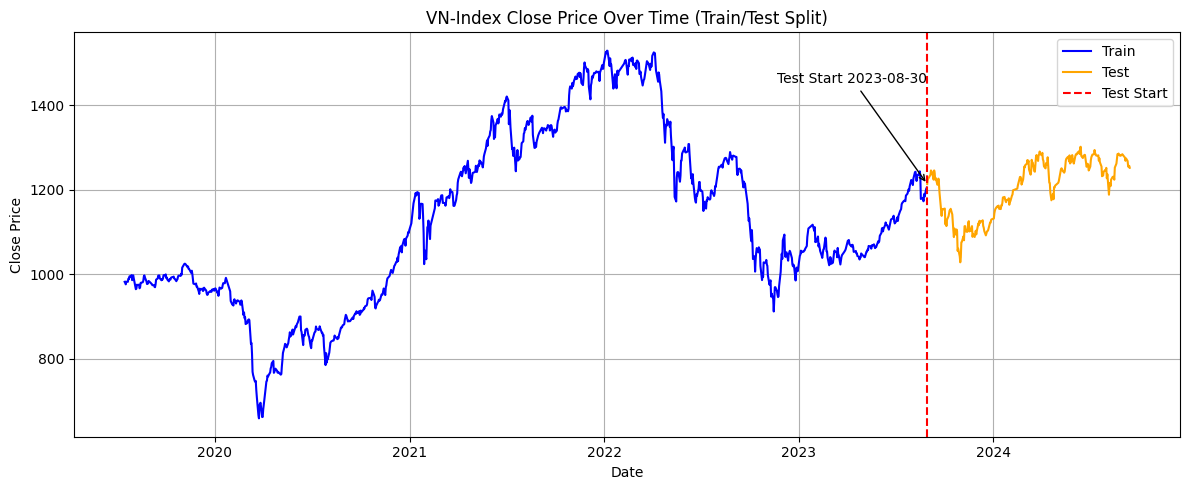

In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import torch.nn as nn
import random
from torch.utils.data import DataLoader, TensorDataset
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.model_selection import train_test_split
from ta import add_all_ta_features
from statsmodels.tsa.stattools import adfuller
from scipy.stats import shapiro, jarque_bera
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import seaborn as sns

def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) 
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ================================
# 1. Load data and compute indicators
# ================================

data = pd.read_csv('VNI.csv')
data = data.drop(['Unnamed: 0.1', 'Unnamed: 0', 'Market',
             'Symbol', 'Time', 'Value'], axis=1)
data['Date'] = pd.to_datetime(data['Date'], dayfirst=True)  # dayfirst=True because of format DD/MM/YYYY
data.set_index('Date', inplace=True)
data = data.loc['2019-07-16':]
data.columns = ['Open', 'High', 'Low', 'Close', 'Volume']
ohclv = ['Open', 'High', 'Low', 'Close', 'Volume']
df = data.copy(deep=True)
data_indicators = add_all_ta_features(
    df, open="Open", high="High", low="Low", close="Close", volume="Volume",
    fillna=True)
features = data.columns.tolist()

# Plot original Close price series with train/test split
split_idx = int(len(df) * 0.8)
date_train = df.index[:split_idx]
date_test = df.index[split_idx:]

plt.figure(figsize=(12, 5))
plt.plot(date_train, df['Close'][:split_idx], label='Train', color='blue')
plt.plot(date_test, df['Close'][split_idx:], label='Test', color='orange')
plt.title('VN-Index Close Price Over Time (Train/Test Split)')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.axvline(x=df.index[split_idx], color='red', linestyle='--', label='Test Start')
plt.annotate(f"Test Start {df.index[split_idx].strftime('%Y-%m-%d')}",
             xy=(df.index[split_idx], df['Close'][split_idx]),
             xytext=(df.index[split_idx], df['Close'].max()*0.95),
             arrowprops=dict(facecolor='red', arrowstyle='->'),
             horizontalalignment='right')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

        count         mean         std     min     25%      50%      75%  \
Close  1293.0  1139.816551  187.887581  659.21  992.45  1149.02  1269.09   

           max  skewness  kurtosis  
Close  1528.57  0.015065 -0.596903  


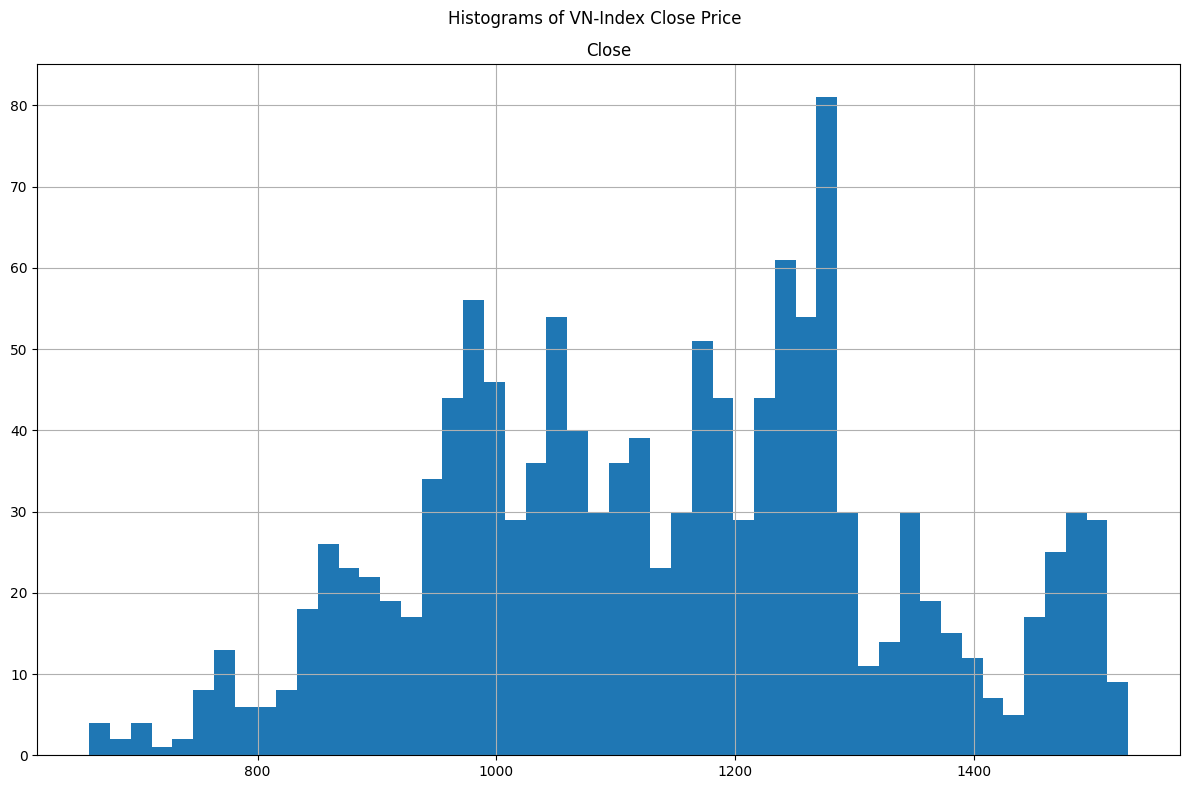

In [3]:
# ================================
# 2. Run Descriptive Statistics and Tests
# ================================

numeric_cols = ['Close']
# Descriptive statistics + skewness + kurtosis
desc_stats = data[numeric_cols].describe().T
desc_stats['skewness'] = data[numeric_cols].skew()
desc_stats['kurtosis'] = data[numeric_cols].kurtosis()

print(desc_stats)

# Plot histogram
data[numeric_cols].hist(bins=50, figsize=(12, 8), layout=(1, 1))
plt.suptitle("Histograms of VN-Index Close Price")
plt.tight_layout()
plt.show()


In [4]:
# ADF Test + Shapiro + JB
def run_stat_tests(series, name):
    series = series.dropna()

    # ADF Test
    adf_result = adfuller(series)
    adf_stat = adf_result[0]
    adf_p = adf_result[1]

    # Shapiro-Wilk Test
    shapiro_stat, shapiro_p = shapiro(series)

    # Jarque-Bera Test
    jb_stat, jb_p = jarque_bera(series)

    return {
        'ADF Statistic': adf_stat,
        'ADF p-value': adf_p,
        'Shapiro p-value': shapiro_p,
        'Jarque-Bera p-value': jb_p
    }

# Apply to each column
results = []
for col in numeric_cols:
    res = run_stat_tests(data[col], col)
    res['Feature'] = col
    results.append(res)

# Create DataFrame results
test_results = pd.DataFrame(results).set_index('Feature')
print(test_results.round(4))

         ADF Statistic  ADF p-value  Shapiro p-value  Jarque-Bera p-value
Feature                                                                  
Close          -1.4619       0.5523              0.0               0.0001


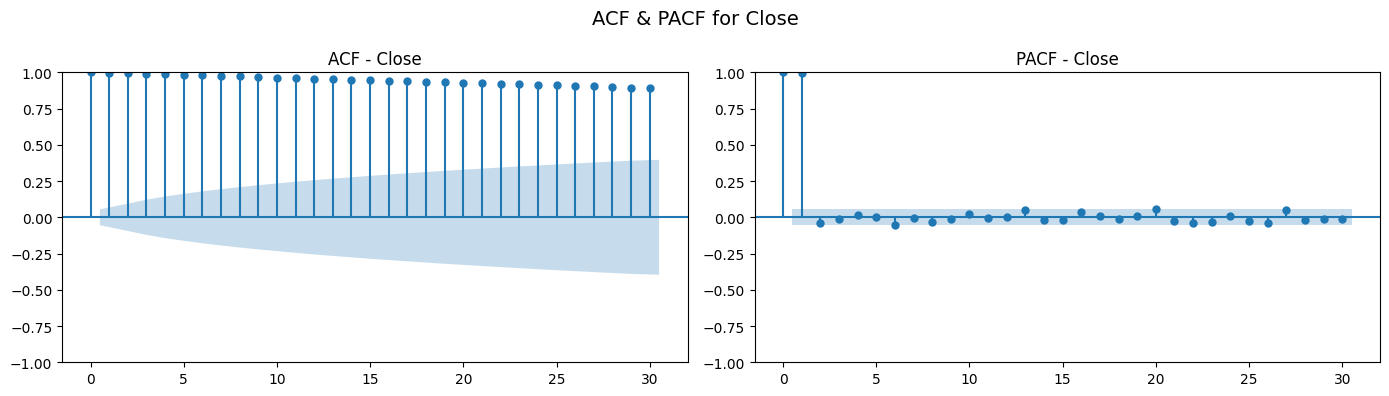

In [5]:
# Maximum lags to be plotted
max_lag = 30

# Plot ACF and PACF
for col in numeric_cols:
    series = data[col].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'ACF & PACF for {col}', fontsize=14)

    plot_acf(series, ax=axes[0], lags=max_lag, title=f'ACF - {col}')
    plot_pacf(series, ax=axes[1], lags=max_lag, title=f'PACF - {col}', method='ywm')  # 'ywm' for financial data

    plt.tight_layout()
    plt.show()

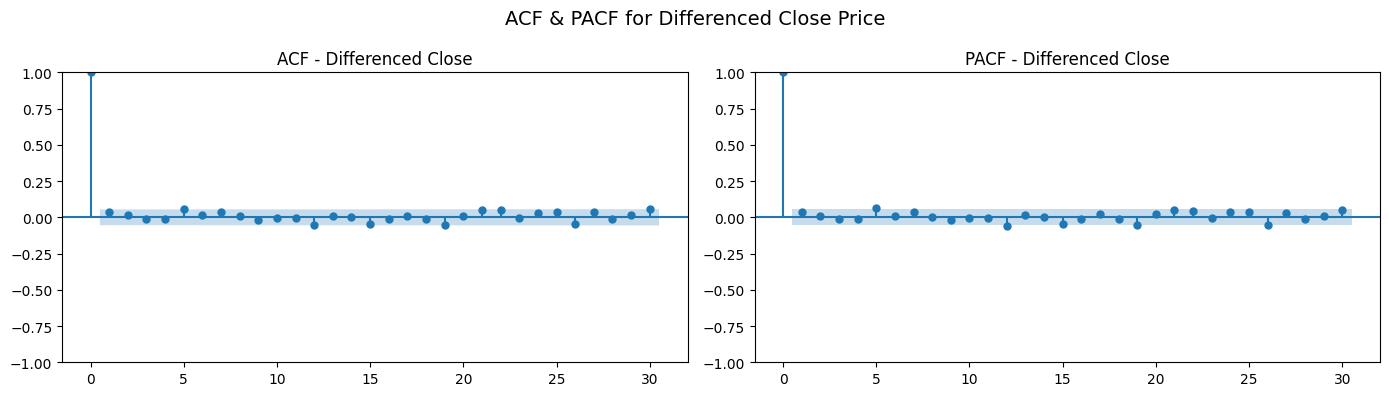

In [6]:
# First-order differencing
diff_close = data['Close'].diff().dropna()

# Plot ACF and PACF
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('ACF & PACF for Differenced Close Price', fontsize=14)

plot_acf(diff_close, ax=axes[0], lags=30, title='ACF - Differenced Close')
plot_pacf(diff_close, ax=axes[1], lags=30, title='PACF - Differenced Close', method='ywm')

plt.tight_layout()
plt.show()

/Users/chaupham/anaconda3/envs/chaupmbn/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/chaupham/anaconda3/envs/chaupmbn/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/chaupham/anaconda3/envs/chaupmbn/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/Users/chaupham/anaconda3/envs/chaupmbn/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given wit

ARIMA      -> RMSE: 68.62, MAE: 60.63
ARIMAX     -> RMSE: 65.86, MAE: 58.15


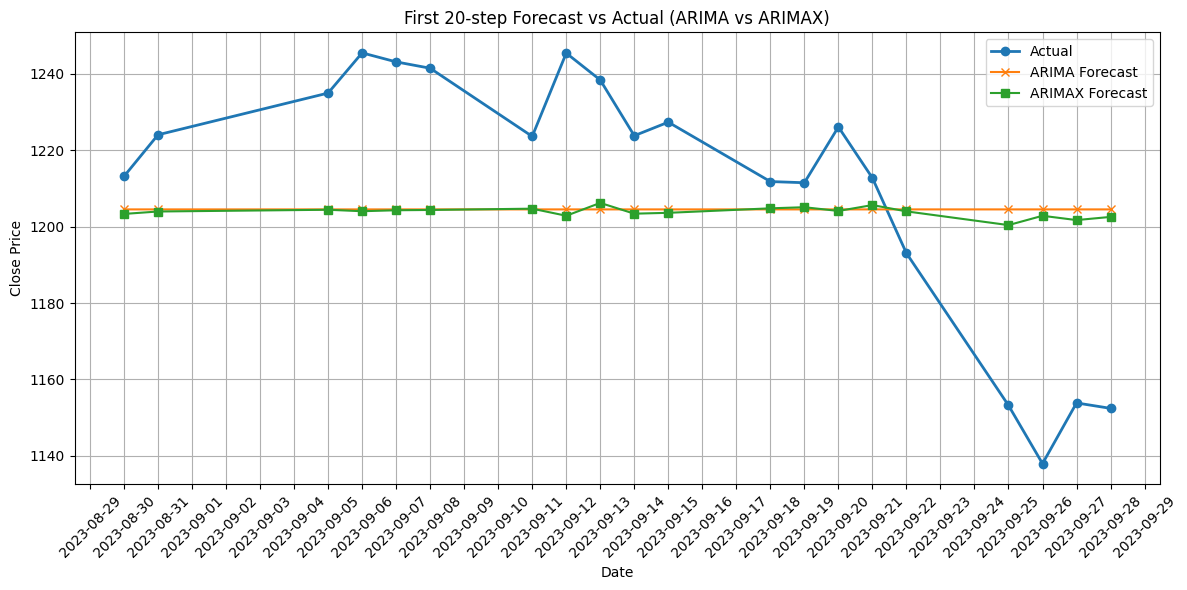

In [7]:
# ================================
# 3. ARIMA and ARIMAX
# ================================

# Train-Test split
train_size = int(len(data) * 0.8)
train_ar = data['Close'][:train_size].tolist()
test_ar = data['Close'][train_size:].tolist()

exog_vars = ['Open', 'High', 'Low', 'Volume']

# ARIMA
model_arima = ARIMA(train_ar, order=(1, 1, 1))
model_arima_fit = model_arima.fit()
forecast_arima = model_arima_fit.forecast(steps=len(test_ar))

# ARIMAX
train_exog = data[exog_vars][:train_size]
test_exog = data[exog_vars][train_size:]

model_arimax = SARIMAX(train_ar[1:], exog=train_exog[:-1], order=(1, 1, 1),
                       enforce_stationarity=False, enforce_invertibility=False)
model_arimax_fit = model_arimax.fit(disp=False)
forecast_arimax = model_arimax_fit.forecast(steps=len(test_ar)+1, exog=pd.concat([train_exog.iloc[[-1]],test_exog]))

# Evaluation
actual = data['Close'][train_size:train_size + len(test_ar)].values

def evaluate_forecast(name, actual, predicted):
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    print(f"{name:<10} -> RMSE: {rmse:.2f}, MAE: {mae:.2f}")

evaluate_forecast("ARIMA", actual, forecast_arima)
evaluate_forecast("ARIMAX", actual, forecast_arimax[:-1])

forecast_dates = data.index[train_size:train_size + 20]
actual = data['Close'][train_size:train_size + 20].values

plt.figure(figsize=(12, 6))
plt.plot(forecast_dates, actual, label='Actual', marker='o', linewidth=2)
plt.plot(forecast_dates, forecast_arima[:20], label='ARIMA Forecast', marker='x')
plt.plot(forecast_dates, forecast_arimax[:20], label='ARIMAX Forecast', marker='s')

plt.title("First 20-step Forecast vs Actual (ARIMA vs ARIMAX)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend(loc='best')

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=1))
plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:
# ================================
# 4. Preprocess for ML models
# ================================
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_scaled = scaler_X.fit_transform(data[features])
y_scaled = scaler_y.fit_transform(data[['Close']].shift(-1).dropna())
X_scaled = X_scaled[:-1]  # Align

window_size = 10
X_seq, y_seq = [], []
for i in range(len(X_scaled) - window_size):
    X_seq.append(X_scaled[i:i+window_size])
    y_seq.append(y_scaled[i+window_size])
X_seq = np.array(X_seq)
y_seq = np.array(y_seq)

X_train, X_test, y_train, y_test = train_test_split(X_seq, y_seq, shuffle=False, test_size=0.2)
X_test = np.concatenate([X_test, X_train[-3:-1]], axis=0)
y_test = np.concatenate([y_test, y_train[-3:-1]], axis=0)
X_train_torch = torch.tensor(X_train, dtype=torch.float32).permute(0,2,1)
X_test_torch = torch.tensor(X_test, dtype=torch.float32).permute(0,2,1)

In [44]:
# ================================
# 5. Define Models
# ================================
class CNN1D_Only(nn.Module):
    def __init__(self, in_channels):
        set_seed(42)
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, 64, kernel_size=2)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64 * ((window_size - 1) // 2), 1)
        
    def forward(self, x):
        set_seed(42)
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x_flat = self.flatten(x)
        output = self.fc(x_flat)
        return output, x_flat

class CNN2D_Only(nn.Module):
    def __init__(self):
        set_seed(42)
        super().__init__()
        self.conv = nn.Conv2d(1, 64, kernel_size=(3,3), padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d((2,2))
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(64 * (window_size//2) * (len(features)//2), 1)
    
    def forward(self, x):
        set_seed(42)
        x = self.conv(x)
        x = self.relu(x)
        x = self.pool(x)
        x_flat = self.flatten(x)
        output = self.fc(x_flat)
        return output, x_flat

# ================================
# 6. CNN Pre-training
# ================================
X_train_2d = torch.tensor(X_train[:, :, :].reshape(-1, 1, window_size, len(features)), dtype=torch.float32)
X_test_2d = torch.tensor(X_test[:, :, :].reshape(-1, 1, window_size, len(features)), dtype=torch.float32)

cnn1d_only_model = CNN1D_Only(in_channels=X_train_torch.shape[1])
cnn2d_only_model = CNN2D_Only()

criterion = nn.MSELoss()
optimizer1 = torch.optim.Adam(cnn1d_only_model.parameters(), lr=0.001)
optimizer2 = torch.optim.Adam(cnn2d_only_model.parameters(), lr=0.001)

for epoch in range(20):
    set_seed(42)
    cnn1d_only_model.train()
    optimizer1.zero_grad()
    out1, _ = cnn1d_only_model(X_train_torch)
    loss1 = criterion(out1.squeeze(), torch.tensor(y_train.ravel(), dtype=torch.float32))
    loss1.backward()
    optimizer1.step()

    cnn2d_only_model.train()
    optimizer2.zero_grad()
    out2, _ = cnn2d_only_model(X_train_2d)
    loss2 = criterion(out2.squeeze(), torch.tensor(y_train.ravel(), dtype=torch.float32))
    loss2.backward()
    optimizer2.step()

# ================================
# 7. Feature Extraction + SVM
# ================================

# 7.1 Use pretrained CNN1D and CNN2D to extract features
cnn1d_only_model.eval()
cnn2d_only_model.eval()

with torch.no_grad():
    _, cnn1d_train_feat = cnn1d_only_model(X_train_torch)
    _, cnn1d_test_feat = cnn1d_only_model(X_test_torch)
    
    _, cnn2d_train_feat = cnn2d_only_model(X_train_2d)
    _, cnn2d_test_feat = cnn2d_only_model(X_test_2d)

cnn1d_train_feat_np = cnn1d_train_feat.numpy()
cnn1d_test_feat_np = cnn1d_test_feat.numpy()

cnn2d_train_feat_np = cnn2d_train_feat.numpy()
cnn2d_test_feat_np = cnn2d_test_feat.numpy()

# 7.2 SVM models on pretrained CNN features

svm_cnn1d = SVR(kernel='rbf')
svm_cnn1d.fit(cnn1d_train_feat_np, y_train.ravel())
y_pred_cnn1d = svm_cnn1d.predict(cnn1d_test_feat_np)

svm_cnn2d = SVR(kernel='rbf')
svm_cnn2d.fit(cnn2d_train_feat_np, y_train.ravel())
y_pred_cnn2d = svm_cnn2d.predict(cnn2d_test_feat_np)


# ================================
# 8. Inverse Transform and Align
# ================================

# Inverse transform y_test (ground truth)
y_test_inv = scaler_y.inverse_transform(y_test.reshape(-1, 1))

# Inverse transform all predictions
y_pred_svm_inv = scaler_y.inverse_transform(y_pred_svm.reshape(-1, 1))
y_pred_cnn1d_inv = scaler_y.inverse_transform(y_pred_cnn1d.reshape(-1, 1))
y_pred_cnn2d_inv = scaler_y.inverse_transform(y_pred_cnn2d.reshape(-1, 1))

# CNN-only predictions (direct output)
y_pred_cnn1d_only, _ = cnn1d_only_model(X_test_torch)
y_pred_cnn2d_only, _ = cnn2d_only_model(X_test_2d)

y_pred_cnn1d_only_inv = scaler_y.inverse_transform(y_pred_cnn1d_only.detach().numpy().reshape(-1, 1))
y_pred_cnn2d_only_inv = scaler_y.inverse_transform(y_pred_cnn2d_only.detach().numpy().reshape(-1, 1))

# Align lengths to avoid broadcasting errors (very important)
min_len = min(
    len(y_test_inv), len(y_pred_svm_inv),
    len(y_pred_cnn1d_inv), len(y_pred_cnn2d_inv),
    len(y_pred_cnn1d_only_inv), len(y_pred_cnn2d_only_inv)
)

# Truncate all arrays to same length (align tail)
test_actual = y_test_inv[-min_len:]
y_pred_svm_inv = y_pred_svm_inv[-min_len:]
y_pred_cnn1d_inv = y_pred_cnn1d_inv[-min_len:]
y_pred_cnn2d_inv = y_pred_cnn2d_inv[-min_len:]
y_pred_cnn1d_only_inv = y_pred_cnn1d_only_inv[-min_len:]
y_pred_cnn2d_only_inv = y_pred_cnn2d_only_inv[-min_len:]

# Align forecast dates for plotting
test_start_idx = len(data) - len(y_test)
forecast_dates = data.index[test_start_idx + (len(y_test) - min_len):]


In [ ]:
# # ================================
# # 8. Inverse Transform and Align
# # ================================
# y_test_inv = scaler_y.inverse_transform(y_test)
# y_pred_svm_inv = scaler_y.inverse_transform(y_pred_svm.reshape(-1,1))
# y_pred_cnn1d_inv = scaler_y.inverse_transform(y_pred_cnn1d.reshape(-1,1))
# y_pred_cnn2d_inv = scaler_y.inverse_transform(y_pred_cnn2d.reshape(-1,1))
# y_pred_cnn1d_only = cnn1d_only_model(X_test_torch).detach().numpy()
# y_pred_cnn2d_only = cnn2d_only_model(X_test_2d).detach().numpy()
# y_pred_cnn1d_only_inv = scaler_y.inverse_transform(y_pred_cnn1d_only.reshape(-1,1))
# y_pred_cnn2d_only_inv = scaler_y.inverse_transform(y_pred_cnn2d_only.reshape(-1,1))

# min_len = min(
#     len(y_test_inv), len(forecast_arima), len(forecast_arima),
#     len(y_pred_svm_inv), len(y_pred_cnn1d_inv), len(y_pred_cnn2d_inv),
#     len(y_pred_cnn1d_only_inv), len(y_pred_cnn2d_only_inv)
# )
# test_actual = y_test_inv[-min_len:]
# test_start_idx = len(data) - len(y_test)
# forecast_dates = data.index[test_start_idx + (len(y_test) - min_len):]


Model Evaluation Metrics:
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 32.22, MAE: 26.57
CNN-2D+SVM      -> RMSE: 36.85, MAE: 32.41
CNN-1D          -> RMSE: 126.14, MAE: 120.33
CNN-2D          -> RMSE: 56.26, MAE: 46.72


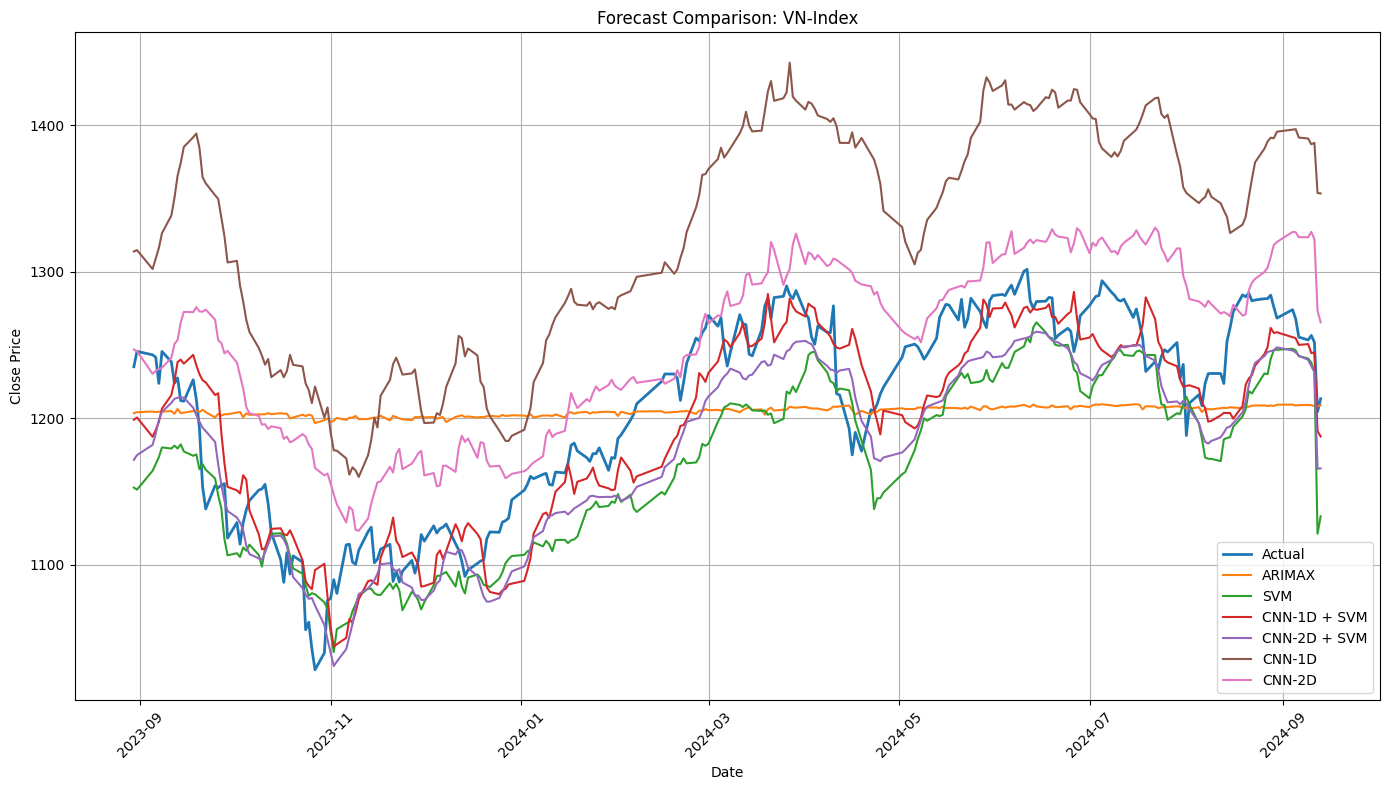

In [45]:
# ================================
# 9. Evaluation and Plot
# ================================
def print_metrics(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:<15} -> RMSE: {rmse:.2f}, MAE: {mae:.2f}")

print("\nModel Evaluation Metrics:")
print_metrics("ARIMAX", test_actual, forecast_arimax[:-1])
print_metrics("SVM", test_actual, y_pred_svm_inv)
print_metrics("CNN-1D+SVM", test_actual, y_pred_cnn1d_inv)
print_metrics("CNN-2D+SVM", test_actual, y_pred_cnn2d_inv)
print_metrics("CNN-1D", test_actual, y_pred_cnn1d_only_inv)
print_metrics("CNN-2D", test_actual, y_pred_cnn2d_only_inv)

plt.figure(figsize=(14, 8))
plt.plot(forecast_dates, test_actual, label="Actual", linewidth=2)
plt.plot(forecast_dates, forecast_arimax[:-1], label="ARIMAX")
plt.plot(forecast_dates, y_pred_svm_inv[-min_len:], label="SVM")
plt.plot(forecast_dates, y_pred_cnn1d_inv[-min_len:], label="CNN-1D + SVM")
plt.plot(forecast_dates, y_pred_cnn2d_inv[-min_len:], label="CNN-2D + SVM")
plt.plot(forecast_dates, y_pred_cnn1d_only_inv[-min_len:], label="CNN-1D")
plt.plot(forecast_dates, y_pred_cnn2d_only_inv[-min_len:], label="CNN-2D")
plt.legend(loc='lower right')
plt.xticks(rotation=45)
plt.title("Forecast Comparison: VN-Index")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.grid(True)
plt.tight_layout()
plt.show()

## Out_channel = 16
Model Evaluation Metrics: (20 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.72, MAE: 26.14
CNN-2D+SVM      -> RMSE: 37.64, MAE: 33.23
CNN-1D          -> RMSE: 210.03, MAE: 205.74
CNN-2D          -> RMSE: 183.19, MAE: 176.84

Model Evaluation Metrics: (50 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.25, MAE: 25.82
CNN-2D+SVM      -> RMSE: 37.43, MAE: 33.02
CNN-1D          -> RMSE: 59.03, MAE: 48.51
CNN-2D          -> RMSE: 39.06, MAE: 29.85

Model Evaluation Metrics: (100 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.22, MAE: 25.83
CNN-2D+SVM      -> RMSE: 37.92, MAE: 33.52
CNN-1D          -> RMSE: 36.78, MAE: 28.84
CNN-2D          -> RMSE: 32.29, MAE: 25.34

Model Evaluation Metrics: (500 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.25, MAE: 26.15
CNN-2D+SVM      -> RMSE: 37.30, MAE: 32.89
CNN-1D          -> RMSE: 27.06, MAE: 20.80
CNN-2D          -> RMSE: 29.11, MAE: 21.97

Model Evaluation Metrics: (1000 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.21, MAE: 26.24
CNN-2D+SVM      -> RMSE: 36.97, MAE: 32.61
CNN-1D          -> RMSE: 24.36, MAE: 19.09
CNN-2D          -> RMSE: 21.89, MAE: 16.48

Model Evaluation Metrics: (2000 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.27, MAE: 26.25
CNN-2D+SVM      -> RMSE: 39.02, MAE: 34.64
CNN-1D          -> RMSE: 23.53, MAE: 18.22
CNN-2D          -> RMSE: 18.79, MAE: 14.17

Model Evaluation Metrics: (5000 epochs)
ARIMAX          -> RMSE: 65.96, MAE: 58.14
SVM             -> RMSE: 46.10, MAE: 40.59
CNN-1D+SVM      -> RMSE: 31.87, MAE: 26.84
CNN-2D+SVM      -> RMSE: 39.69, MAE: 35.32
CNN-1D          -> RMSE: 23.79, MAE: 18.82
CNN-2D          -> RMSE: 17.93, MAE: 13.47

In [35]:
from torchsummary import summary

in_channels = len(features)

print("\n=== CNN1D_Only (Full Model) ===")
summary(CNN1D_Only(in_channels), input_size=(in_channels, window_size))

print("\n=== CNN2D_Only (Full Model) ===")
summary(CNN2D_Only(), input_size=(1, window_size, len(features)))


=== CNN1D_Only (Full Model) ===
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv1d-1                [-1, 16, 9]             176
              ReLU-2                [-1, 16, 9]               0
         MaxPool1d-3                [-1, 16, 4]               0
           Flatten-4                   [-1, 64]               0
            Linear-5                    [-1, 1]              65
Total params: 241
Trainable params: 241
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------

=== CNN2D_Only (Full Model) ===
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1            [-1, 16, 10, 5]